In [1]:
# Linear Regression

In [2]:
# Step 1: Import libraries

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [4]:
# Step 2: Load dataset

In [5]:

df = pd.read_csv("telecom_regression_dataset.csv")

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())


   data_usage  call_duration  plan_type  bill_amount
0   10.049547     608.458730          3   695.356883
1   21.902884     357.879865          3   665.274319
2    7.956519     384.375842          3   550.847293
3    4.618794     108.280089          2   287.242847
4    1.454391     295.619571          3   477.080111

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   data_usage     10000 non-null  float64
 1   call_duration  10000 non-null  float64
 2   plan_type      10000 non-null  int64  
 3   bill_amount    10000 non-null  float64
dtypes: float64(3), int64(1)
memory usage: 312.6 KB
None

Missing Values:
data_usage       0
call_duration    0
plan_type        0
bill_amount      0
dtype: int64

Duplicate Records: 0

Statistical Summary:
         data_usage  call_duration     plan_type   bill

In [6]:
# Step 3: Exploratory Data Analysis

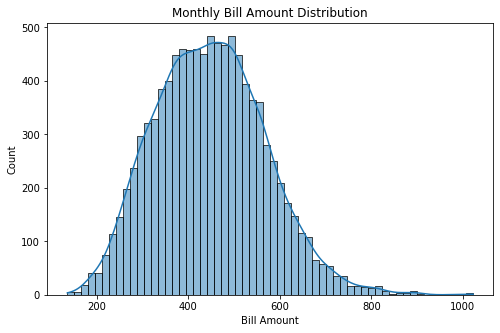

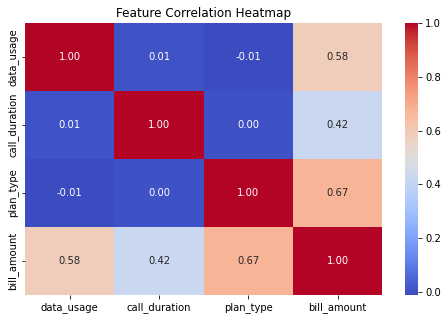

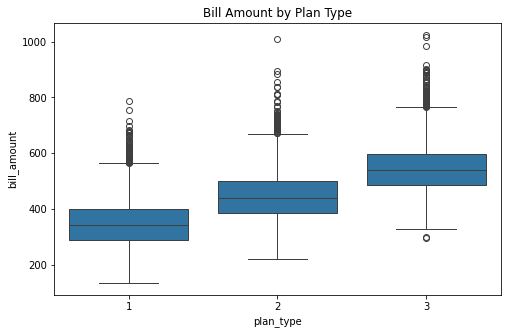

In [7]:

# Distribution of monthly bill amount
plt.figure(figsize=(8, 5))
sns.histplot(df["bill_amount"], kde=True)
plt.title("Monthly Bill Amount Distribution")
plt.xlabel("Bill Amount")
plt.show()

# Correlation heatmap for numeric columns
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

# Average bill by plan type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="plan_type", y="bill_amount")
plt.title("Bill Amount by Plan Type")
plt.show()


In [8]:
# Step 4: Define input features (X) and target (Y)

In [9]:

X = df[["data_usage", "call_duration", "plan_type"]]
y = df["bill_amount"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
   data_usage  call_duration  plan_type
0   10.049547     608.458730          3
1   21.902884     357.879865          3
2    7.956519     384.375842          3
3    4.618794     108.280089          2
4    1.454391     295.619571          3

Target Variable:
0    695.356883
1    665.274319
2    550.847293
3    287.242847
4    477.080111
Name: bill_amount, dtype: float64


In [10]:
# Step 5: Preprocess and split data

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(),
         ["data_usage", "call_duration"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         ["plan_type"])
    ]
)


In [12]:
# Step 6: Build and train Linear Regression

In [13]:

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [14]:
# Step 7: Make predictions

In [15]:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Bill": y_test.values,
    "Predicted Bill": y_pred
})

print(results.head(10))


   Actual Bill  Predicted Bill
0   459.906559      429.663174
1   215.406335      242.389729
2   617.318940      636.118852
3   313.917242      291.032784
4   295.338266      318.269463
5   334.858895      341.704132
6   490.955258      471.772860
7   233.692664      279.490375
8   300.975722      238.985034
9   416.501068      410.668558


In [16]:
# Step 8: Evaluate the model

In [17]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation Results
-------------------------
MAE: 15.838744898709693
MSE: 398.88361980691315
RMSE: 19.972070994439036
R2 Score: 0.9728486083703646


In [18]:
# Step 9: Actual vs predicted visualization

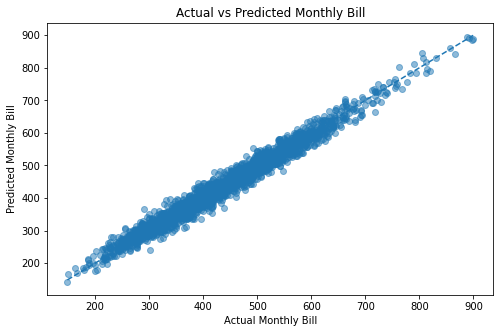

In [19]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Monthly Bill")
plt.ylabel("Predicted Monthly Bill")
plt.title("Actual vs Predicted Monthly Bill")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()


In [20]:
# Step 10: Predict the bill for a new customer

In [21]:

new_customer = pd.DataFrame({
    "data_usage": [15.5],
    "call_duration": [450],
    "plan_type": [2]
})

predicted_bill = model.predict(new_customer)

print("Predicted Monthly Bill Amount:",
      round(predicted_bill[0], 2))


Predicted Monthly Bill Amount: 579.16
